**Passo 1.**
1. Importazione di NumPy e Pandas: Librerie fondamentali in Python per il calcolo numerico, la gestione di array e la manipolazione di tabelle di dati (DataFrame), essenziali per l'analisi e la pulizia del dataset.
2. Importazione di Matplotlib: Modulo principale per la creazione di grafici e la visualizzazione dei dati, conforme alle specifiche viste a lezione per l'esplorazione visiva.
3. Caricamento del Dataset clinico (Dataset_Autism-for-assessment.xlsx): Lettura del foglio di lavoro principale "Risposte del modulo 1" all'interno di un DataFrame di Pandas e verifica preliminare delle dimensioni della tabella.



In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from google.colab import drive
drive.mount('/content/drive')

# Specifichiamo il percorso del file Excel caricato su Colab
file_path = '/content/drive/MyDrive/ColabNotebooks/Dataset_Autism-for-assessment.xlsx'

# Leggiamo il foglio di lavoro principale del dataset
df = pd.read_excel(file_path, sheet_name='Risposte del modulo 1')

# Visualizziamo le dimensioni della tabella (numero di righe e colonne)
print(f"Dimensioni del dataset: {df.shape[0]} righe, {df.shape[1]} colonne")

# Mostriamo le prime righe per un'anteprima dei dati
display(df.head())


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Dimensioni del dataset: 126 righe, 30 colonne


,Data di Nascita** NO NEC,Età cronologica (mesi),Sesso,Problemi in gravidanza,Fenomeni perinatali normoevoluti,Anomalie sono presenti alla nascita,Familiarità per disturbi Psichiatrici,Tipo di familiarità,QS (mesi età-equivalente),Q.I.,...,Tipo di esposizione ambientale,III Specificatore (associazione a condizione genetica nota),Tipo di gene/condizione genetica nota associata,"IV Specificatore (altri disturbi mentali, comportamentali o del neurosviluppo associati)",Comorbidità Psichitriche,Disturbi della Nutrizione e dell'Alimentazione,Selettività alimentare,Alterazioni dell'array-CGH,[Cromosomi alterati],Tipo di mutazione
0,2015-10-24,56.0,Maschio,No,si,NaN,Si,ritardo di linguaggio (linea paterna),44,NaN,...,NaN,Si,SYT1,Si,No,Si,SI,Si,Cromosoma 12,del12q21.2(SYT1)
1,2007-02-15,156.0,Maschio,No,si,NaN,Si,Autismo,NaN,109.0,...,NaN,No,NaN,No,Si,No,NaN,Si,"Cromosoma X, Cromosoma Y","delXq28,delYq12"
2,2007-02-15,156.0,Maschio,No,si,NaN,Si,Autismo,NaN,69.0,...,NaN,No,NaN,Si,Si,Si,SI,Si,"Cromosoma X, Cromosoma Y","delXq28,delYq12"
3,2016-11-21,45.0,Femmina,Sì,no,ipoglicemia neonatale,No,NaN,35 mesi,NaN,...,NaN,No,NaN,Si,No,Si,SI,Si,Cromosoma 1,del1p32.1
4,2016-08-29,48.0,Maschio,Sì,si,NaN,No,NaN,< 24 mesi,NaN,...,NaN,No,NaN,Si,No,Si,SI,Si,"Cromosoma15, Cromosoma 20","dup15q26.1,del20p12.1"


**Passo 2.**
1. Analisi preliminare della variabile target (Livello di gravità): Verifica dei valori unici presenti nel dataset per identificare eventuali disomogeneità o formati misti (es. stringhe descrittive rispetto a valori numerici puri).
2. Rimozione dei valori mancanti non gestibili: Esclusione delle righe in cui il livello di gravità è completamente assente (NaN), poiché non è possibile addestrare un modello di apprendimento supervisionato privo dell'etichetta di classe di riferimento.
3. Normalizzazione dei dati di classe: Applicazione di una funzione di mappatura per uniformare tutte le varianti testuali e numeriche in un formato standard coerente (es. 'Livello 1', 'Livello 2', 'Livello 3').

In [ ]:
# Verifichiamo i valori unici presenti prima della pulizia
print("Valori originali della classe:", df['Livello di gravità'].unique())

# 1. Rimuoviamo le righe dove il 'Livello di gravità' è mancante (NaN)
df_clean = df.dropna(subset=['Livello di gravità']).copy()

# 2. Funzione per uniformare i valori della variabile target in un formato standard
def clean_severity(val):
    val_str = str(val).strip()
    if '1' in val_str:
        return 'Livello 1'
    elif '2' in val_str:
        return 'Livello 2'
    elif '3' in val_str:
        return 'Livello 3'
    return val_str

df_clean['Livello di gravità'] = df_clean['Livello di gravità'].apply(clean_severity)

# Verifichiamo il risultato dopo l'uniformazione con il conteggio delle classi
print("\nDistribuzione delle classi dopo l'uniformazione:")
print(df_clean['Livello di gravità'].value_counts())


Valori originali della classe: ['Livello 2' 'Livello 1' 'Livello 3' 2 1 nan 3]

Distribuzione delle classi dopo l'uniformazione:
Livello di gravità
Livello 2    58
Livello 3    46
Livello 1    19
Name: count, dtype: int64


**Passo 3.**
1. Analisi dei valori nulli: Calcolo della percentuale di valori mancanti (NaN) per ciascuna colonna del dataset pulito, al fine di individuare gli attributi più completi dal punto di vista clinico.
2. Definizione del Dataset Ristretto: Selezione di un sottoinsieme mirato di colonne chiave (come età, sesso, punteggi VABS e ADOS) che presentano una bassa percentuale di valori nulli.
3. Filtraggio dei record incompleti: Rimozione delle righe con valori nulli limitatamente alle colonne selezionate, ottenendo un dataset più popolato di pazienti utile per la fase di addestramento.

In [ ]:
# Calcoliamo la percentuale di valori nulli per ogni colonna nel dataset pulito
null_counts = df_clean.isnull().sum()
null_percentage = (null_counts / len(df_clean)) * 100

# Creiamo un riepilogo ordinato dei valori mancanti
missing_data_df = pd.DataFrame({'Valori Nulli': null_counts, 'Percentuale (%)': null_percentage})
print("Riepilogo valori nulli:")
print(missing_data_df.sort_values(by='Percentuale (%)', ascending=False))

# Creiamo il Dataset Ristretto selezionando le colonne chiave con meno valori mancanti
columns_ristretto = [
    'Età cronologica (mesi)',
    'Sesso',
    'QA (VABS)',
    'ADOS (punteggio di comparazione)',
    'Livello di gravità'
]

df_ristretto = df_clean[columns_ristretto].dropna().copy()
print(f"\nDimensioni del Dataset Ristretto: {df_ristretto.shape}")
display(df_ristretto.head())

# Verifichiamo il risultato dopo l'uniformazione con il conteggio delle classi
print("\nDistribuzione delle classi DF ristretto:")
print(df_ristretto['Livello di gravità'].value_counts())


Riepilogo valori nulli:
                                                    Valori Nulli  \
Tipo di gene/condizione genetica nota associata              121   
Tipo di esposizione ambientale                               119   
Condizione medica associata                                  112   
Anomalie sono presenti alla nascita                          105   
I Specificatore (con o senza compromissione int...           102   
 Q.I.                                                         92   
Tipo di familiarità                                           68   
Selettività alimentare                                        67   
 [Cromosomi alterati]                                         59   
Tipo di mutazione                                             59   
III Specificatore (associazione a condizione me...            57   
III Specificatore (associazione a condizione ge...            57   
Comorbidità Psichitriche                                      57   
Disturbi della Nutrizion

,Età cronologica (mesi),Sesso,QA (VABS),ADOS (punteggio di comparazione),Livello di gravità
0,56.0,Maschio,53.0,7.0,Livello 2
1,156.0,Maschio,78.0,7.0,Livello 1
2,156.0,Maschio,56.0,10.0,Livello 2
3,45.0,Femmina,56.0,6.0,Livello 3
4,48.0,Maschio,54.0,6.0,Livello 3



Distribuzione delle classi DF ristretto:
Livello di gravità
Livello 2    37
Livello 3    31
Livello 1    12
Name: count, dtype: int64


**Passo 4.**
1. Preparazione dei dati per il clustering: Selezione delle feature numeriche rilevanti ed esclusione della variabile target (Livello di gravità), coerentemente con l'approccio non supervisionato basato su dati non etichettati visto a lezione.
2. Standardizzazione delle feature: Normalizzazione delle variabili tramite StandardScaler per evitare che attributi con ordini di grandezza differenti influenzino negativamente il calcolo delle distanze geometriche dell'algoritmo K-Means.
3. Applicazione dell'algoritmo K-Means: Esecuzione del partizionamento non supervisionato impostando $k = 3$ (in accordo con i livelli di gravità) e analisi della distribuzione dei campioni all'interno dei cluster individuati.

In [ ]:

from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

# Selezioniamo le feature numeriche per il clustering (escludendo la classe)
features_cluster = ['Età cronologica (mesi)', 'QA (VABS)', 'ADOS (punteggio di comparazione)']
X_cluster = df_ristretto[features_cluster].copy()

# 1. Standardizzazione delle feature (fondamentale per le distanze nel K-Means)
scaler = StandardScaler()
X_cluster_scaled = scaler.fit_transform(X_cluster)

# 2. Applicazione del K-Means (ipotizziamo 3 cluster in accordo con i livelli di gravità)
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
df_ristretto['Cluster'] = kmeans.fit_predict(X_cluster_scaled)

# 3. Verifichiamo la distribuzione dei campioni nei cluster trovati
print("Distribuzione dei campioni nei cluster trovati:")
print(df_ristretto['Cluster'].value_counts())
display(df_ristretto.head())
#confronto gruppi k means con livelli di gravità
pd.crosstab(df_ristretto['Cluster'], df_ristretto['Livello di gravità'])

Distribuzione dei campioni nei cluster trovati:
Cluster
1    39
0    27
2    14
Name: count, dtype: int64


,Età cronologica (mesi),Sesso,QA (VABS),ADOS (punteggio di comparazione),Livello di gravità,Cluster
0,56.0,Maschio,53.0,7.0,Livello 2,1
1,156.0,Maschio,78.0,7.0,Livello 1,2
2,156.0,Maschio,56.0,10.0,Livello 2,2
3,45.0,Femmina,56.0,6.0,Livello 3,1
4,48.0,Maschio,54.0,6.0,Livello 3,1


Livello di gravità,Livello 1,Livello 2,Livello 3
Cluster,,,
0,7,14,6
1,2,17,20
2,3,6,5


**Passo 5.**
1. reparazione delle feature e della variabile target: Definizione della matrice degli input ($X$) e dell'etichetta di classe ($y$) a partire dal dataset ristretto pulito, convertendo opportunamente gli attributi categoriali in formato numerico.
2. Addestramento e validazione del modello supervisionato: Applicazione dell'algoritmo di classificazione ad Albero di Decisione (Decision Tree), supportato dalla Cross-Validation e dalla suddivisione del set di dati per valutare la capacità di generalizzazione su dati non visti.
3. Valutazione tramite metriche e Matrice di Confusione: Calcolo delle metriche di performance (Accuracy, Precision, Recall, F-score) e visualizzazione della matrice di confusione per analizzare dettagliatamente gli errori e i successi del classificatore.

['Maschio' 'Femmina' 'M' 'F']
Accuratezza media con Cross-Validation (5-fold): 0.51 (+/- 0.06)

Report di Classificazione sul test set:
              precision    recall  f1-score   support

   Livello 1       0.33      0.67      0.44         3
   Livello 2       0.67      0.57      0.62         7
   Livello 3       0.75      0.50      0.60         6

    accuracy                           0.56        16
   macro avg       0.58      0.58      0.55        16
weighted avg       0.64      0.56      0.58        16


Distribuzione delle classi nel Test Set
Livello di gravità
Livello 2    7
Livello 3    6
Livello 1    3
Name: count, dtype: int64


<Figure size 600x400 with 0 Axes>

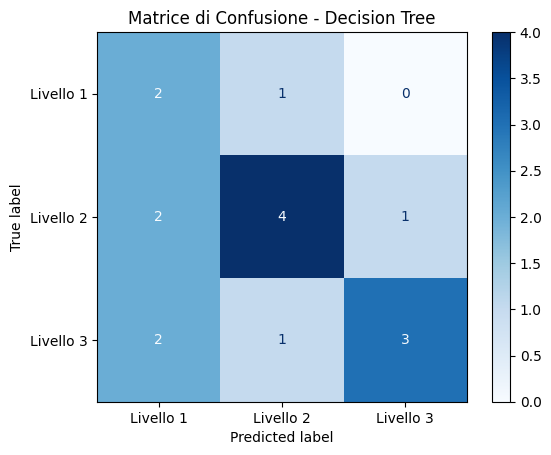

In [ ]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# 1. Prepariamo le feature (X) e la variabile target (y)
df_model = df_ristretto.copy()
# Convertiamo la variabile 'Sesso' in numerica (1 per maschio, 0 per femmina)
print(df_model['Sesso'].unique())
df_model['Sesso_Num'] = df_model['Sesso'].apply(lambda x: 1 if str(x).strip().lower() in ['maschio', 'm', 'male'] else 0)

features_ml = ['Età cronologica (mesi)', 'QA (VABS)', 'ADOS (punteggio di comparazione)', 'Sesso_Num']
X = df_model[features_ml]
y = df_model['Livello di gravità']


# 2. Suddivisione in Training e Test set (come visto nel workflow delle slide)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42,stratify = y)

# Inizializziamo e addestriamo il classificatore Decision Tree
dtc = DecisionTreeClassifier(random_state=42, max_depth=3)
dtc.fit(X_train, y_train)

# Valutazione con Cross-Validation per una stima robusta
cv_scores = cross_val_score(dtc, X, y, cv=5, scoring='accuracy')
print(f"Accuratezza media con Cross-Validation (5-fold): {cv_scores.mean():.2f} (+/- {cv_scores.std():.2f})")

# Predizione sul test set
y_pred = dtc.predict(X_test)

# 3. Stampiamo le metriche di classificazione (Accuracy, Precision, Recall, F-score)
print("\nReport di Classificazione sul test set:")
print(classification_report(y_test, y_pred, zero_division=0))

# Verifichiamo il risultato dopo l'uniformazione con il conteggio delle classi
print("\nDistribuzione delle classi nel Test Set")
print(y_test.value_counts())


# Visualizzazione della Matrice di Confusione (vista a lezione)
cm = confusion_matrix(y_test, y_pred, labels=dtc.classes_)
plt.figure(figsize=(6, 4))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=dtc.classes_)
disp.plot(cmap=plt.cm.Blues, values_format='d')
plt.title("Matrice di Confusione - Decision Tree")
plt.grid(False)
plt.show()
